# EXPERIMENT 8
## Generation of Synthetic Images Using a Generative Adversarial Network (GAN)

**Name:** Saravanan P  
**Register Number:** 24BAD105  
**Dataset:** MNIST handwritten digits  
**Platform:** Google Colab (TensorFlow / Keras)



# IN-LAB EXERCISE

## PART A: DATASET PREPARATION

**Aim:** Load the MNIST dataset, inspect image dimensions and pixel range, normalize the images, and prepare batches for GAN training.

Name: Saravanan P
Register Number: 24BAD105
Experiment 8: Generation of Synthetic Images Using GAN
TensorFlow version: 2.21.0
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images shape: (60000, 28, 28)
Testing images shape: (10000, 28, 28)
Image data type before normalization: uint8
Pixel range before normalization: 0 to 255


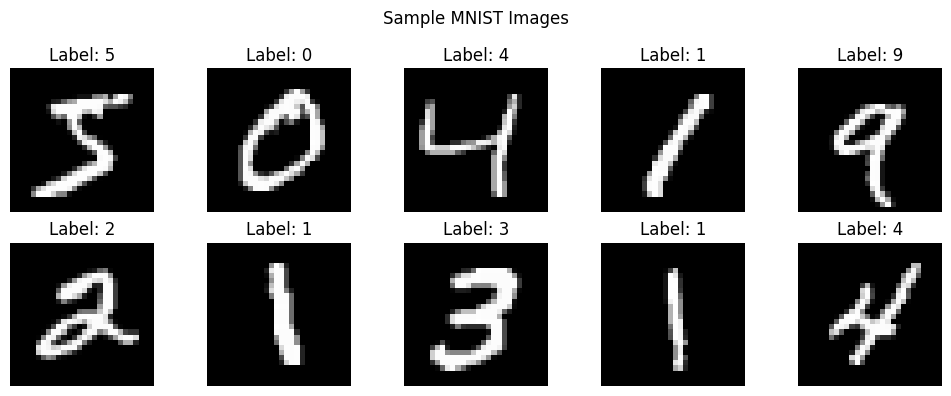


After normalization and reshaping:
Training image shape: (60000, 28, 28, 1)
Normalized pixel range: -1.0 to 1.0
Number of training batches: 234


In [4]:
# EXPERIMENT 8 - GAN
# Name: Saravanan P
# Register Number: 24BAD105

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

print("Name: Saravanan P")
print("Register Number: 24BAD105")
print("Experiment 8: Generation of Synthetic Images Using GAN")
print("TensorFlow version:", tf.__version__)

# Set random seeds for more repeatable results
tf.random.set_seed(42)
np.random.seed(42)

# Load MNIST handwritten digit dataset
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

print("Training images shape:", x_train.shape)
print("Testing images shape:", x_test.shape)
print("Image data type before normalization:", x_train.dtype)
print("Pixel range before normalization:", x_train.min(), "to", x_train.max())

# Display sample original images
plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")
plt.suptitle("Sample MNIST Images")
plt.tight_layout()
plt.show()

# GAN Generator uses tanh output, so normalize images to [-1, 1]
x_train = (x_train.astype("float32") - 127.5) / 127.5

# Add channel dimension: (number of images, 28, 28, 1)
x_train = np.expand_dims(x_train, axis=-1)

print("\nAfter normalization and reshaping:")
print("Training image shape:", x_train.shape)
print("Normalized pixel range:", float(x_train.min()), "to", float(x_train.max()))

# Prepare batches of real images
BUFFER_SIZE = x_train.shape[0]
BATCH_SIZE = 256

train_dataset = (
    tf.data.Dataset.from_tensor_slices(x_train)
    .shuffle(BUFFER_SIZE)
    .batch(BATCH_SIZE, drop_remainder=True)
    .prefetch(tf.data.AUTOTUNE)
)

print("Number of training batches:", tf.data.experimental.cardinality(train_dataset).numpy())

## PART B: IMPLEMENTING THE GENERATOR AND DISCRIMINATOR

**Aim:** Build a Generator that creates images from random noise and a Discriminator that classifies images as real or generated. Combine them to form the GAN.

In [5]:
# Define GAN parameters
NOISE_DIM = 100

# -------------------------
# GENERATOR
# -------------------------
def build_generator():
    model = tf.keras.Sequential(name="Generator")
    model.add(tf.keras.layers.Input(shape=(NOISE_DIM,)))
    model.add(tf.keras.layers.Dense(7 * 7 * 256, use_bias=False))
    model.add(tf.keras.layers.BatchNormalization())
    model.add(tf.keras.layers.ReLU())
    model.add(tf.keras.layers.Reshape((7, 7, 256)))

    model.add(tf.keras.layers.Conv2DTranspose(
        128, kernel_size=5, strides=1, padding="same", use_bias=False
    ))
    model.add(tf.keras.layers.BatchNormalization())
    model.add(tf.keras.layers.ReLU())

    model.add(tf.keras.layers.Conv2DTranspose(
        64, kernel_size=5, strides=2, padding="same", use_bias=False
    ))
    model.add(tf.keras.layers.BatchNormalization())
    model.add(tf.keras.layers.ReLU())

    # Output is a 28 x 28 grayscale image with pixel values in [-1, 1]
    model.add(tf.keras.layers.Conv2DTranspose(
        1, kernel_size=5, strides=2, padding="same", use_bias=False,
        activation="tanh"
    ))
    return model

# -------------------------
# DISCRIMINATOR
# -------------------------
def build_discriminator():
    model = tf.keras.Sequential(name="Discriminator")
    model.add(tf.keras.layers.Input(shape=(28, 28, 1)))
    model.add(tf.keras.layers.Conv2D(
        64, kernel_size=5, strides=2, padding="same"
    ))
    model.add(tf.keras.layers.LeakyReLU(negative_slope=0.2))
    model.add(tf.keras.layers.Dropout(0.3))

    model.add(tf.keras.layers.Conv2D(
        128, kernel_size=5, strides=2, padding="same"
    ))
    model.add(tf.keras.layers.LeakyReLU(negative_slope=0.2))
    model.add(tf.keras.layers.Dropout(0.3))

    model.add(tf.keras.layers.Flatten())
    # One logit: larger values indicate more likely real images
    model.add(tf.keras.layers.Dense(1))
    return model

# Create both models
generator = build_generator()
discriminator = build_discriminator()

# Display model summaries
print("GENERATOR SUMMARY")
generator.summary()

print("\nDISCRIMINATOR SUMMARY")
discriminator.summary()

# Create the complete GAN by passing Generator output to Discriminator
noise_input = tf.keras.layers.Input(shape=(NOISE_DIM,))
generated_image = generator(noise_input)
gan_output = discriminator(generated_image)
gan_model = tf.keras.Model(noise_input, gan_output, name="GAN")

print("\nCOMPLETE GAN SUMMARY")
gan_model.summary()

GENERATOR SUMMARY


Model: "Generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 12544)          │     1,254,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 12544)          │        50,176 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 7, 7, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 7, 7, 128)      │       819,200 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 7, 7, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 14, 14, 64)     │       204,800 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 28, 28, 1)      │         1,600 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,330,944 (8.89 MB)

 Trainable params: 2,305,472 (8.79 MB)

 Non-trainable params: 25,472 (99.50 KB)

... (8 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Generator (Sequential)          │ (None, 28, 28, 1)      │     2,330,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Discriminator (Sequential)      │ (None, 1)              │       212,865 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,543,809 (9.70 MB)

 Trainable params: 2,518,337 (9.61 MB)

 Non-trainable params: 25,472 (99.50 KB)

## PART C: GAN TRAINING AND PERFORMANCE MONITORING

**Aim:** Train the Discriminator with real and generated images, train the Generator to fool the Discriminator, and record both losses.

Epoch 1/10 | Generator Loss: 0.6813 | Discriminator Loss: 1.2597


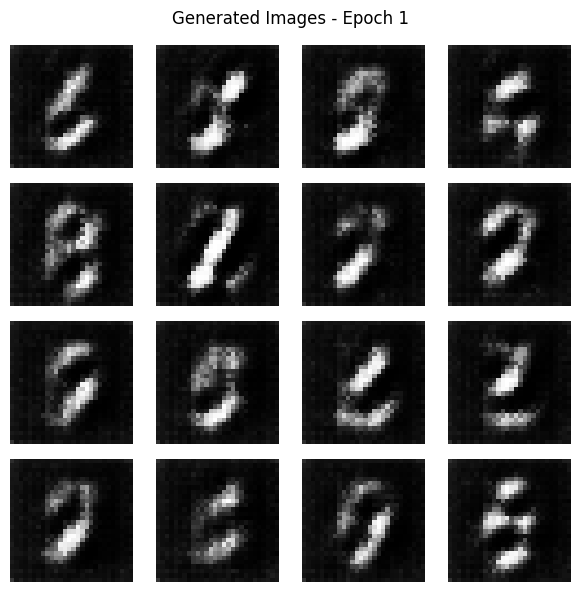

Epoch 2/10 | Generator Loss: 0.8049 | Discriminator Loss: 1.2595


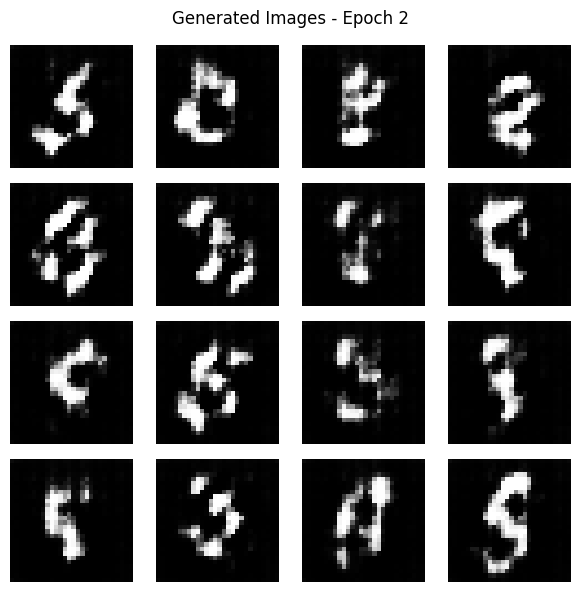

Epoch 3/10 | Generator Loss: 0.7903 | Discriminator Loss: 1.3143
Epoch 4/10 | Generator Loss: 0.7717 | Discriminator Loss: 1.3278


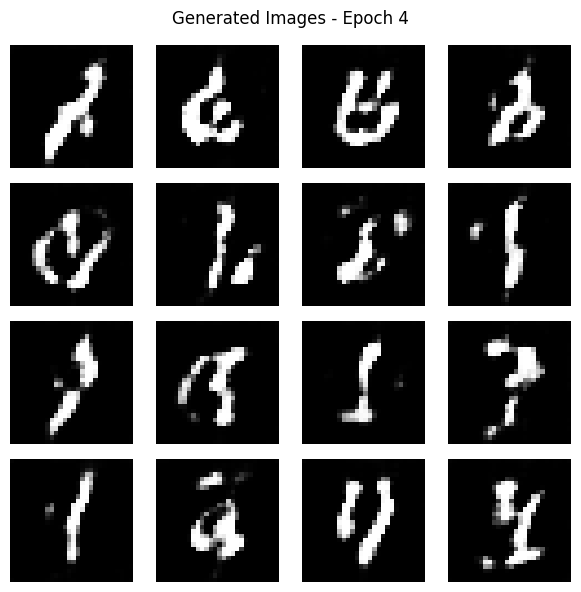

Epoch 5/10 | Generator Loss: 0.7682 | Discriminator Loss: 1.3338
Epoch 6/10 | Generator Loss: 0.7549 | Discriminator Loss: 1.3480


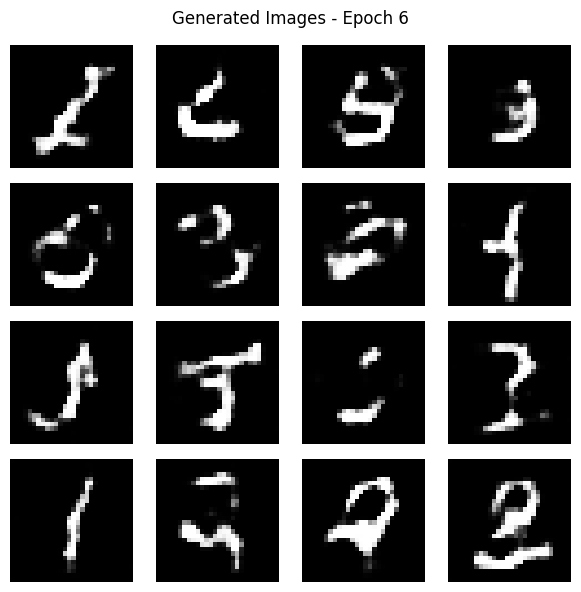

Epoch 7/10 | Generator Loss: 0.7331 | Discriminator Loss: 1.3607
Epoch 8/10 | Generator Loss: 0.7239 | Discriminator Loss: 1.3647


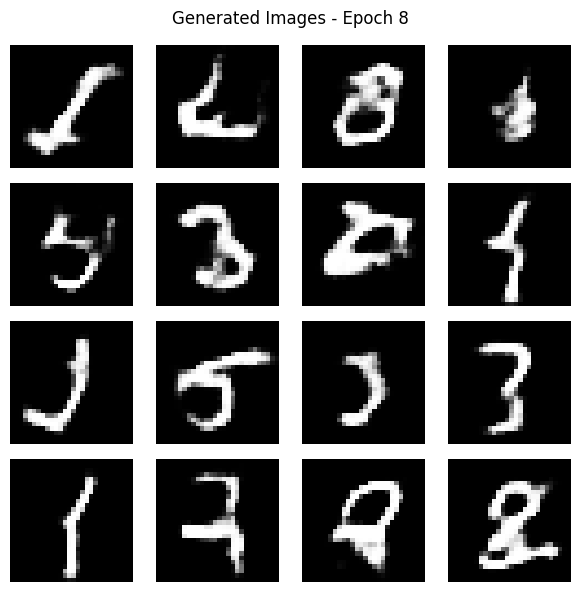

Epoch 9/10 | Generator Loss: 0.7297 | Discriminator Loss: 1.3687
Epoch 10/10 | Generator Loss: 0.7263 | Discriminator Loss: 1.3687


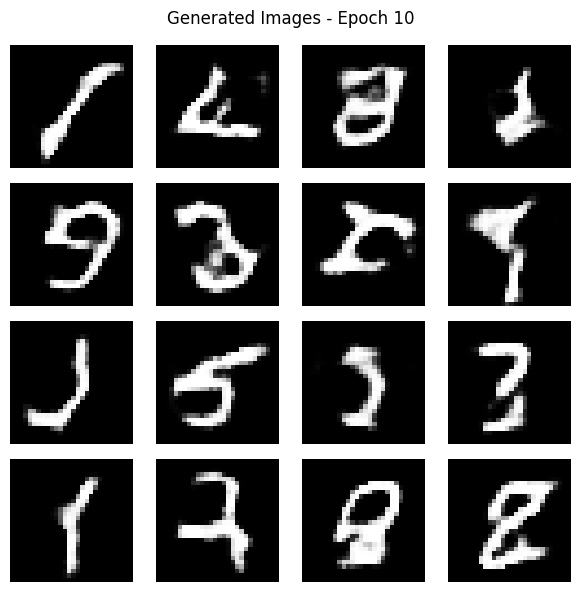

GAN training completed successfully.


In [6]:
# Binary cross-entropy is used with logits (the Discriminator has no sigmoid output)
cross_entropy = tf.keras.losses.BinaryCrossentropy(from_logits=True)

# Discriminator loss: classify real images as 1 and generated images as 0
def discriminator_loss(real_output, fake_output):
    real_loss = cross_entropy(tf.ones_like(real_output), real_output)
    fake_loss = cross_entropy(tf.zeros_like(fake_output), fake_output)
    return real_loss + fake_loss

# Generator loss: make generated images be classified as real (label 1)
def generator_loss(fake_output):
    return cross_entropy(tf.ones_like(fake_output), fake_output)

# Separate optimizers for the two networks
generator_optimizer = tf.keras.optimizers.Adam(learning_rate=0.0001, beta_1=0.5)
discriminator_optimizer = tf.keras.optimizers.Adam(learning_rate=0.0001, beta_1=0.5)

# One training step: update Discriminator, then update Generator
@tf.function
def train_step(real_images):
    batch_size = tf.shape(real_images)[0]

    # Train Discriminator
    noise = tf.random.normal([batch_size, NOISE_DIM])
    with tf.GradientTape() as disc_tape:
        generated_images = generator(noise, training=True)
        real_output = discriminator(real_images, training=True)
        fake_output = discriminator(generated_images, training=True)
        disc_loss = discriminator_loss(real_output, fake_output)

    disc_gradients = disc_tape.gradient(
        disc_loss, discriminator.trainable_variables
    )
    discriminator_optimizer.apply_gradients(
        zip(disc_gradients, discriminator.trainable_variables)
    )

    # Train Generator
    noise = tf.random.normal([batch_size, NOISE_DIM])
    with tf.GradientTape() as gen_tape:
        generated_images = generator(noise, training=True)
        fake_output = discriminator(generated_images, training=True)
        gen_loss = generator_loss(fake_output)

    gen_gradients = gen_tape.gradient(
        gen_loss, generator.trainable_variables
    )
    generator_optimizer.apply_gradients(
        zip(gen_gradients, generator.trainable_variables)
    )

    return gen_loss, disc_loss

# Fixed noise lets us compare generated samples across epochs
NUM_EXAMPLES = 16
fixed_noise = tf.random.normal([NUM_EXAMPLES, NOISE_DIM])

def display_generated_images(model, epoch):
    predictions = model(fixed_noise, training=False)
    predictions = (predictions + 1.0) / 2.0  # Convert [-1, 1] to [0, 1]

    plt.figure(figsize=(6, 6))
    for i in range(NUM_EXAMPLES):
        plt.subplot(4, 4, i + 1)
        plt.imshow(predictions[i, :, :, 0], cmap="gray")
        plt.axis("off")
    plt.suptitle(f"Generated Images - Epoch {epoch}")
    plt.tight_layout()
    plt.show()

# Train GAN
EPOCHS = 10  # Increase to 20 or more for potentially better results

generator_losses = []
discriminator_losses = []

for epoch in range(1, EPOCHS + 1):
    gen_epoch_loss = tf.keras.metrics.Mean()
    disc_epoch_loss = tf.keras.metrics.Mean()

    for real_batch in train_dataset:
        gen_loss, disc_loss = train_step(real_batch)
        gen_epoch_loss.update_state(gen_loss)
        disc_epoch_loss.update_state(disc_loss)

    g_loss_value = float(gen_epoch_loss.result().numpy())
    d_loss_value = float(disc_epoch_loss.result().numpy())
    generator_losses.append(g_loss_value)
    discriminator_losses.append(d_loss_value)

    print(
        f"Epoch {epoch}/{EPOCHS} | "
        f"Generator Loss: {g_loss_value:.4f} | "
        f"Discriminator Loss: {d_loss_value:.4f}"
    )

    # Display generated images every 2 epochs and at the final epoch
    if epoch % 2 == 0 or epoch == 1 or epoch == EPOCHS:
        display_generated_images(generator, epoch)

print("GAN training completed successfully.")

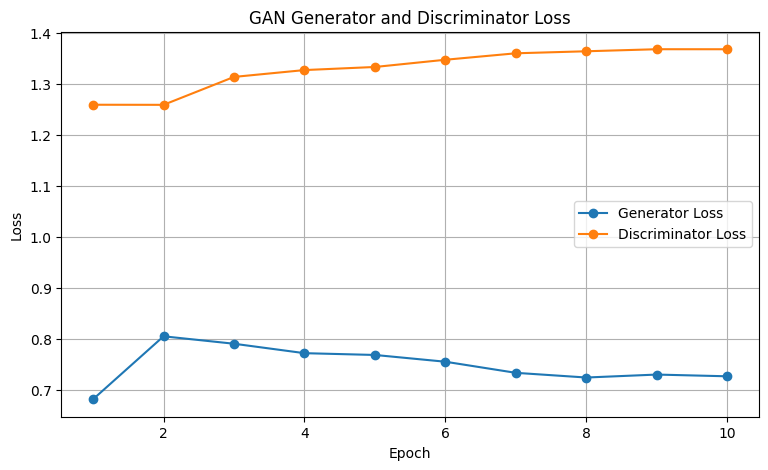

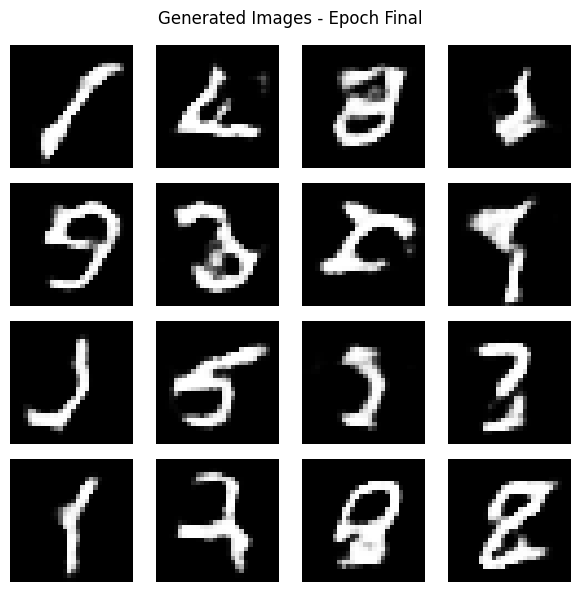

Final Generator Loss: 0.726312518119812
Final Discriminator Loss: 1.3686556816101074


In [7]:
# Plot Generator and Discriminator losses
plt.figure(figsize=(9, 5))
plt.plot(range(1, EPOCHS + 1), generator_losses, marker="o", label="Generator Loss")
plt.plot(range(1, EPOCHS + 1), discriminator_losses, marker="o", label="Discriminator Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("GAN Generator and Discriminator Loss")
plt.legend()
plt.grid(True)
plt.show()

# Display final set of synthetic images
display_generated_images(generator, "Final")

print("Final Generator Loss:", generator_losses[-1])
print("Final Discriminator Loss:", discriminator_losses[-1])

## PART D: GENERATING AND COMPARING SYNTHETIC IMAGES

**Aim:** Generate synthetic images using the trained Generator, compare them with original MNIST images, and visually inspect quality, diversity, and recognizability.

**Note about the lab manual:** Part D also mentions movie-review sentences, an LSTM model, and Encoder latent representations. These instructions do not match this experiment's GAN architecture. The GAN-specific tasks below—generating synthetic images and comparing them with real samples—are implemented here.

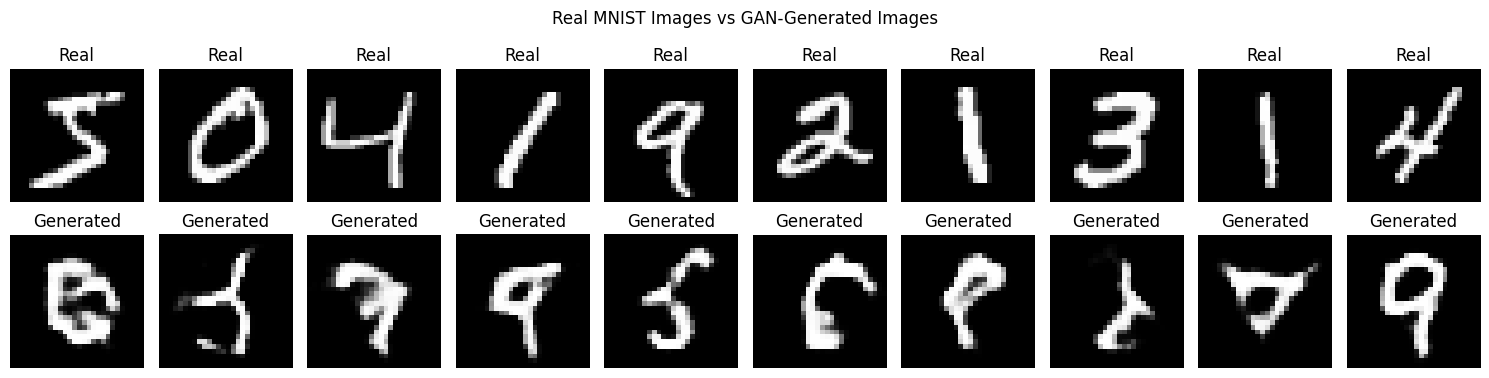

Number of synthetic images generated: 10
Synthetic image dimensions: (28, 28, 1)
Synthetic pixel range: 0.0 to 0.9999951124191284


In [8]:
# Generate a fresh set of synthetic images
num_generated = 10
new_noise = tf.random.normal([num_generated, NOISE_DIM])
synthetic_images = generator(new_noise, training=False)
synthetic_images = (synthetic_images + 1.0) / 2.0  # Scale to [0, 1]

# Display original MNIST images and synthetic images side by side
plt.figure(figsize=(15, 4))

for i in range(num_generated):
    # Real image
    plt.subplot(2, num_generated, i + 1)
    real_image = (x_train[i, :, :, 0] + 1.0) / 2.0
    plt.imshow(real_image, cmap="gray")
    plt.title("Real")
    plt.axis("off")

    # Generated image
    plt.subplot(2, num_generated, i + 1 + num_generated)
    plt.imshow(synthetic_images[i, :, :, 0], cmap="gray")
    plt.title("Generated")
    plt.axis("off")

plt.suptitle("Real MNIST Images vs GAN-Generated Images")
plt.tight_layout()
plt.show()

print("Number of synthetic images generated:", synthetic_images.shape[0])
print("Synthetic image dimensions:", synthetic_images.shape[1:])
print("Synthetic pixel range:", float(tf.reduce_min(synthetic_images)),
      "to", float(tf.reduce_max(synthetic_images)))

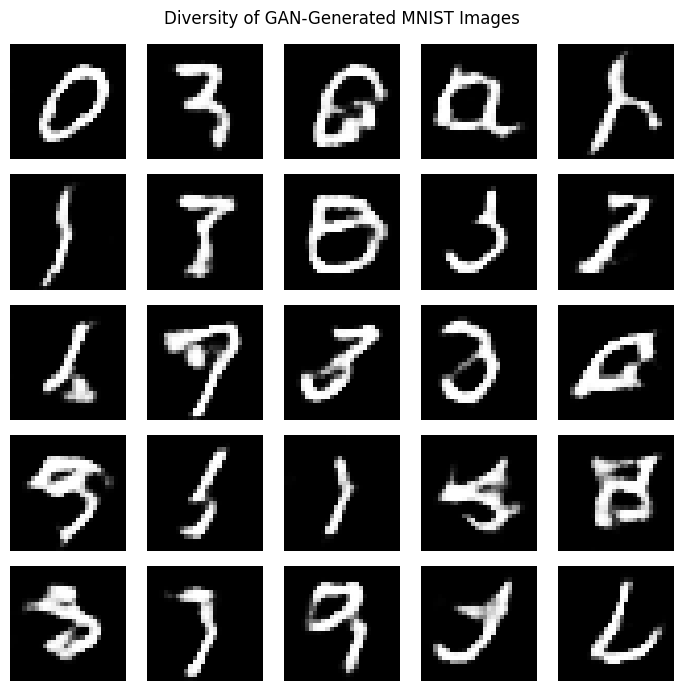

Observation guide:
1. Check whether generated images resemble handwritten digits.
2. Check whether the generated samples look different from one another.
3. Note that early training may produce unclear or noisy images.
4. GAN quality is assessed visually here; no numerical image-quality metric is calculated.


In [9]:
# Visual inspection helper: display a larger grid of generated samples
noise_for_grid = tf.random.normal([25, NOISE_DIM])
generated_grid = generator(noise_for_grid, training=False)
generated_grid = (generated_grid + 1.0) / 2.0

plt.figure(figsize=(7, 7))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.imshow(generated_grid[i, :, :, 0], cmap="gray")
    plt.axis("off")
plt.suptitle("Diversity of GAN-Generated MNIST Images")
plt.tight_layout()
plt.show()

print("Observation guide:")
print("1. Check whether generated images resemble handwritten digits.")
print("2. Check whether the generated samples look different from one another.")
print("3. Note that early training may produce unclear or noisy images.")
print("4. GAN quality is assessed visually here; no numerical image-quality metric is calculated.")